In [ ]:
from google.colab import files
import pandas as pd

df = pd.read_excel("MAFLD Data Final Merged.xlsx")
df.head()

,SubmissionDate,Today,I7,end,deviceid,unique id,Gender,age,recruitment_details-date_of_intial_visit,Medical history,...,KEY,SubmitterID,SubmitterName,AttachmentsPresent,AttachmentsExpected,Status,ReviewState,DeviceID,Edits,FormVersion
0,2025-10-13T11:12:51.710Z,2025-10-13,2025-10-13T12:05:21.534+05:30,2025-10-13T15:26:12.541+05:30,collect:LyP1i2tmZI1ET95b,1140.0,1,35,2025-10-13,1 2,...,uuid:6a753694-0b3b-4ba0-ab69-b71e54ddc152,308,MAFLD,0,0,NaN,NaN,collect:LyP1i2tmZI1ET95b,0,2025091611
1,2025-10-06T11:13:24.825Z,2025-10-06,2025-10-06T10:43:32.421+05:30,2025-10-06T16:08:26.491+05:30,collect:LyP1i2tmZI1ET95b,1021.0,1,35,2025-10-06,1,...,uuid:c39d527b-2c1a-4cae-89f1-22aee59b2ddb,308,MAFLD,0,0,NaN,NaN,collect:LyP1i2tmZI1ET95b,0,2025091611
2,2025-11-11T08:35:20.699Z,2025-11-11,2025-11-11T10:23:38.122+05:30,2025-11-11T12:55:22.797+05:30,collect:cF5vZuaCXMLr90zP,3100.0,1,35,2025-11-11,1,...,uuid:3213bd49-c0af-4425-96ae-4424155e2570,308,MAFLD,0,0,NaN,NaN,collect:cF5vZuaCXMLr90zP,0,2025091612
3,2025-10-15T09:01:29.968Z,2025-10-15,2025-10-15T11:47:59.899+05:30,2025-10-15T14:28:38.497+05:30,collect:cF5vZuaCXMLr90zP,3007.0,1,35,2025-10-15,1 2,...,uuid:44b4220d-c16b-48f4-9fae-2cbe8452a9d5,308,MAFLD,0,0,NaN,NaN,collect:cF5vZuaCXMLr90zP,0,2025091611
4,2025-10-15T09:01:27.747Z,2025-10-15,2025-10-15T11:12:24.869+05:30,2025-10-15T14:26:35.330+05:30,collect:cF5vZuaCXMLr90zP,3004.0,2,35,2025-10-15,1,...,uuid:beb9eb47-422c-4245-a5b3-604f368a5904,308,MAFLD,0,0,NaN,NaN,collect:cF5vZuaCXMLr90zP,0,2025091611


In [ ]:
for col in df.columns:
    print(col)

SubmissionDate
Today
I7
end
deviceid
unique id
Gender
age
recruitment_details-date_of_intial_visit
Medical history
medical_family_history-disease_others
Diabetes duration
hypertension duration
fatty_liver_block-fatty_know
fatty_liver_block-fatty_know_others
fatty_liver_block-diagnosis_date
fatty_liver_block-diagnosis_method
fatty_liver_block-diagnosis_method_others
fatty_liver_block-treatment_status
fatty_liver_block-end_note
Alcohol ever
Alcohol 12m
Alcohol drinks
Alcohol duration
Smoking habbit
Tobacco type
behavioural_risk_factors-tobacco_details-tobacco_type_others
bp_measurement-systolic_1
bp_measurement-diastolic_1
bp_measurement-BP1_updateTime
bp_measurement-BP1_recordTime
bp_measurement-systolic_2
bp_measurement-diastolic_2
bp_measurement-BP2_updateTime
bp_measurement-systolic_3
bp_measurement-diastolic_3
bp_measurement-BP3_updateTime
bp_measurement-avg_systolic
bp_measurement-avg_diastolic
Height
weight
bmi
BMI category
anthropometric_measurement-show_bmi
Waist circumference
H

In [ ]:
df['non_invasive_scoring-fib_4_risk'] = df['non_invasive_scoring-fib_4_risk'].replace({
    'Low risk: Advanced fibrosis unlikely. Continue primary care,lifestyle changes,recheck in 1-3 years.': 'Low',
    'Intermediaterisk : Cannot exclude advanced fibrosis. Action : Arrange Fibroscan or refer to specialist for further assessment': 'Intermediate',
    'High risk advanced fibrosis likely. Action refer to hepatology/ gastroenterology urgently': 'High'
})
df['non_invasive_scoring-fib_4_risk'].value_counts()

,count
non_invasive_scoring-fib_4_risk,
Low,438
Intermediate,91
High,8


In [ ]:
df["behavioural_risk_factors-tobacco_details-tobacco_type_others"].unique()

array([nan, 'Pan', 'Jardha', 'Thambak', 'Paan', 'Jarda',
       'Jadha type of tobacco', 'Jardha type of tobacco'], dtype=object)

In [ ]:
df["medical_family_history-disease_others"].unique()

array([nan, 'Thyroid', 'PCI intervention', 'Pci', 'TB', 'Copd',
       'Percutaneous  coronary  intervention 5 years back',
       'Diabetic neuropathy', 'CABG'], dtype=object)

In [ ]:
df['Medical history'].head(10)

,Medical history
0,1 2
1,1
2,1
3,1 2
4,1
5,1 2 9
6,1 2
7,1
8,1 2
9,1 2 9


In [ ]:
df['Medical history'].isnull().sum()

np.int64(0)

In [ ]:
df['Medical history'] = df['Medical history'].astype(str)

In [ ]:
medical = {
    '1':'Diabetes',
    '2':'Hypertension',
    '3':'CKD',
    '4':'Respiratory Disease',
    '5':'CAD',
    '6':'Dyslipidemia',
    '7':'Thyroid'
}
for code, disease in medical.items():
    df[disease] = df['Medical history'].apply(
        lambda x: 1 if code in x.split() else 0
    )

In [ ]:
# Clean the Others text column
df['medical_family_history-disease_others'] = (
    df['medical_family_history-disease_others']
    .fillna('')
    .str.strip()
    .str.lower()
)

# Diabetes
diabetes = ['diabetic neuropathy']
df.loc[
    df['medical_family_history-disease_others'].isin(diabetes),
    'Diabetes'
] = 1

# CAD
cad = [
    'pci',
    'pci intervention',
    'percutaneous  coronary  intervention 5 years back',
    'cabg'
]
df.loc[
    df['medical_family_history-disease_others'].isin(cad),
    'CAD'
] = 1

resp = ['tb', 'copd']

df.loc[
    df['medical_family_history-disease_others'].isin(resp),
    'Respiratory_Disease'
] = 1
df.loc[
    df['medical_family_history-disease_others'].isin(resp),
    'Respiratory Disease'
] = 1

# Others
others = [
    'thyroid'
]
df.loc[
    df['medical_family_history-disease_others'].isin(others),
    'Thyroid'
] = 1

In [ ]:
df[[
    'Medical history',
    'Diabetes',
    'Hypertension',
    'CKD',
    'Respiratory Disease',
    'CAD',
    'Dyslipidemia',
    'Thyroid'
]].head(20)

,Medical history,Diabetes,Hypertension,CKD,Respiratory Disease,CAD,Dyslipidemia,Thyroid
0,1 2,1,1,0,0,0,0,0
1,1,1,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0
3,1 2,1,1,0,0,0,0,0
4,1,1,0,0,0,0,0,0
5,1 2 9,1,1,0,0,0,0,1
6,1 2,1,1,0,0,0,0,0
7,1,1,0,0,0,0,0,0
8,1 2,1,1,0,0,0,0,0
9,1 2 9,1,1,0,0,0,0,1


In [ ]:
print(df['medical_family_history-disease_others'].unique())

['' 'thyroid' 'pci intervention' 'pci' 'tb' 'copd'
 'percutaneous  coronary  intervention 5 years back' 'diabetic neuropathy'
 'cabg']


In [ ]:
# hypertension duration column remove
df.drop(columns=['hypertension duration'], inplace=True)

In [ ]:
df[['Medical history', 'Hypertension']].head(20)

,Medical history,Hypertension
0,1 2,1
1,1,0
2,1,0
3,1 2,1
4,1,0
5,1 2 9,1
6,1 2,1
7,1,0
8,1 2,1
9,1 2 9,1


In [ ]:
df['Medical history'].value_counts().head(20)

,count
Medical history,
1 2,296
1,160
1 2 9,22
1 9,15
1 2 6,9
1 2 5 9,6
2 1,6
1 6,5
1 2 5,5


In [ ]:
df['Hypertension'].value_counts()

,count
Hypertension,
1,354
0,183


In [ ]:
df.drop(columns=['Medical history'], inplace=True)

In [ ]:
df['Smoking habbit'].unique()

array([2, 1])

In [ ]:

df['Smoking habbit'].value_counts()

,count
Smoking habbit,
2,405
1,132


In [ ]:
df['Tobacco type'].value_counts()

,count
Tobacco type,
6,49
1,34
3,31
1 3,7
2,5
3 6,1
2 3,1
3 1,1
4,1


In [ ]:
df['Tobacco type'].unique()

array([nan, '1', '3', '1 3', '6', '3 6', '2', '2 3', '3 1', '4', '1 3 4',
       '1 6'], dtype=object)

In [ ]:
df['Tobacco type'] = df['Tobacco type'].fillna('').astype(str)

In [ ]:
tobacco_map = {
    '1': 'Cigarettes',
    '2': 'Beedis',
    '3': 'Chewing_tobacco',
    '4': 'Snuff',
    '5': 'Hookah',
    '6': 'Other_Tobacco'
}

for code, name in tobacco_map.items():
    df[name] = df['Tobacco type'].apply(
        lambda x: 1 if code in x.split() else 0
    )

In [ ]:
# Values moved from Other_Tobacco to Chewing_tobacco
chewing_items = [
    'Pan',
    'Paan',
    'Jardha',
    'Jarda',
    'Jardha type of tobacco',
    'Jadha type of tobacco',
    'Thambak'
]

mask = df['behavioural_risk_factors-tobacco_details-tobacco_type_others'].isin(chewing_items)

# Move to Chewing_tobacco
df.loc[mask, 'Chewing_tobacco'] = 1

# Remove from Other_Tobacco
df.loc[mask, 'Other_Tobacco'] = 0

In [ ]:
df[['Tobacco type',
    'Cigarettes',
    'Beedis',
    'Chewing_tobacco',
    'Snuff',
    'Hookah',
    'Other_Tobacco']].head(10)

,Tobacco type,Cigarettes,Beedis,Chewing_tobacco,Snuff,Hookah,Other_Tobacco
0,,0,0,0,0,0,0
1,1,1,0,0,0,0,0
2,,0,0,0,0,0,0
3,1,1,0,0,0,0,0
4,,0,0,0,0,0,0
5,,0,0,0,0,0,0
6,,0,0,0,0,0,0
7,3,0,0,1,0,0,0
8,,0,0,0,0,0,0
9,,0,0,0,0,0,0


In [ ]:
df.drop(columns=['Tobacco type'], inplace=True)

In [ ]:
df['Alcohol ever'].unique()

array([1, 2])

In [ ]:
# Alcohol ever = 2 (No) na alcohol details 0
mask = df['Alcohol ever'] == '2'

df.loc[mask, 'Alcohol 12m'] = 0
df.loc[mask, 'Alcohol drinks'] = 0
df.loc[mask, 'Alcohol duration'] = 0

In [ ]:
# Alcohol details missing na 0
df['Alcohol 12m'] = df['Alcohol 12m'].fillna(0)
df['Alcohol drinks'] = df['Alcohol drinks'].fillna(0)
df['Alcohol duration'] = df['Alcohol duration'].fillna(0)

In [ ]:

print(df['Alcohol 12m'].unique())
print(df['Alcohol drinks'].unique())
print(df['Alcohol duration'].unique())

[1. 0. 6. 3. 4. 5. 2.]
[4. 0. 1. 2. 3.]
[3. 0. 1. 2.]


In [ ]:
df_original = pd.read_excel("/content/MAFLD Data Final Merged.xlsx")

print(df_original['Central Obesity'].unique())

['Central Obesity' 'No']


In [ ]:
df['Central Obesity'] = (
    df['Central Obesity']
    .astype(str)
    .str.strip()
    .map({
        'Central Obesity': 1,
        'No': 0
    })
)

In [ ]:
print(df['Central Obesity'].unique())
print(df['Central Obesity'].value_counts())

[1 0]
Central Obesity
1    323
0    214
Name: count, dtype: int64


In [ ]:
target = 'non_invasive_scoring-fib_4_risk'

In [ ]:
features = [
    'Gender',
    'age',

    # Medical history
      'Diabetes',
      'Hypertension',
      'CKD',
      'Respiratory Disease',
      'CAD',
      'Dyslipidemia',
      'Thyroid',
      'HIS Category',

    'Diabetes duration',

    # Alcohol
    #'Alcohol ever',
    'Alcohol 12m',
    'Alcohol drinks',
    'Alcohol duration',


    # Tobacco
    #'Tobacco type',
    'Cigarettes',
    'Beedis',
    'Chewing_tobacco',
    'Snuff',
    'Hookah',

    'bp_measurement-avg_systolic',
    'bmi',
    'Waist circumference',
    'Hip circumference',
    'Waist hip ratio',
    'Central Obesity'
]

In [ ]:
features = [
    'Gender',
    'age',

    # Medical history
      'Diabetes',
      'Hypertension',
      'CKD',
      'Respiratory Disease',
      'CAD',
      'Dyslipidemia',
      'Thyroid',
      'HIS Category',

    'bp_measurement-avg_systolic',
    'bmi',
    'Waist circumference',
    'Hip circumference',
    'Waist hip ratio',
    'Central Obesity'
]

In [ ]:
X = df[features]
y = df[target]

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoders = {}

categorical_cols = [
    'Gender',

    'Diabetes',
    'Hypertension',
    'CKD',
    'Respiratory Disease',
    'CAD',
    'Dyslipidemia',
    'Thyroid',
    'HIS Category',

    'Alcohol 12m',
    'Alcohol drinks',
    'Alcohol duration',

    'Cigarettes',
    'Beedis',
    'Chewing_tobacco',
    'Snuff',
    'Hookah',

    'Central Obesity'
]

for col in categorical_cols:

    if col in X.columns:

        le = LabelEncoder()

        X[col] = le.fit_transform(X[col])

        label_encoders[col] = le


/tmp/ipykernel_2669/2044370692.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = le.fit_transform(X[col])
/tmp/ipykernel_2669/2044370692.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[col] = le.fit_transform(X[col])
/tmp/ipykernel_2669/2044370692.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_g

In [ ]:
X.columns

Index(['Gender', 'age', 'Diabetes', 'Hypertension', 'CKD',
       'Respiratory Disease', 'CAD', 'Dyslipidemia', 'Thyroid', 'HIS Category',
       'bp_measurement-avg_systolic', 'bmi', 'Waist circumference',
       'Hip circumference', 'Waist hip ratio', 'Central Obesity'],
      dtype='object')

In [ ]:
target_encoder = LabelEncoder()

y = target_encoder.fit_transform(y)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [ ]:
import pandas as pd

pd.crosstab(
    X_train['Gender'],
    y_train,
    rownames=['Gender'],
    colnames=['Target']
)


Target,0,1,2
Gender,,,
0,5,44,143
1,1,19,163


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

model.fit(X_train_smote, y_train_smote)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=5000, random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression

model_2 = LogisticRegression(
    max_iter=5000,
    random_state=42
)

model_2.fit(X_train, y_train)

LogisticRegression(max_iter=5000, random_state=42)

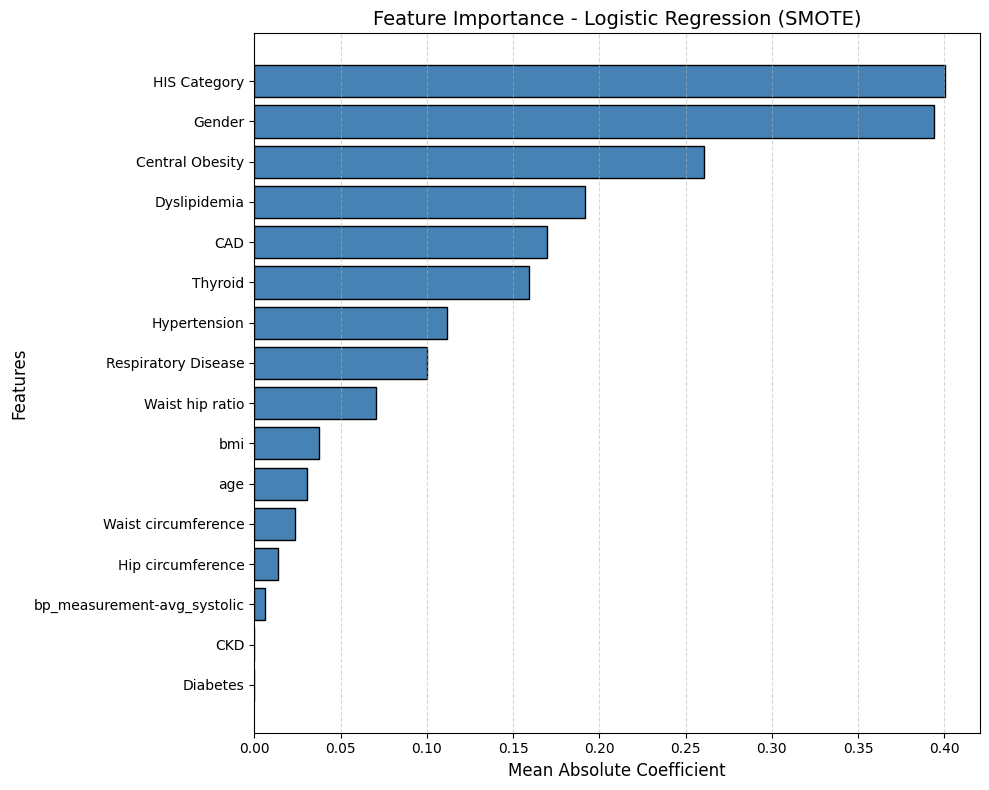

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert SMOTE data to DataFrame (if needed)
X_train_df = pd.DataFrame(X_train, columns=X.columns)

# Calculate feature importance
importance = pd.DataFrame({
    'Feature': X_train_df.columns,
    'Importance': np.mean(np.abs(model_2.coef_), axis=0)
})

# Sort for plotting
importance = importance.sort_values(by='Importance', ascending=True)

# Plot
plt.figure(figsize=(10,8))

plt.barh(
    importance['Feature'],
    importance['Importance'],
    color='steelblue',
    edgecolor='black'
)

plt.xlabel('Mean Absolute Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Importance - Logistic Regression (SMOTE)', fontsize=14)

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy : {accuracy*100:.2f}%")

Accuracy : 59.26%


In [ ]:
from sklearn.preprocessing import LabelEncoder
from scipy.stats import pearsonr

# Create a copy
df_corr = df.copy()

# Initialize encoders
le_hsi = LabelEncoder()
le_fib4 = LabelEncoder()

# Encode dynamically based on unique values
df_corr['HSI_encoded'] = le_hsi.fit_transform(df_corr['HIS Category'].astype(str))
df_corr['FIB4_encoded'] = le_fib4.fit_transform(df_corr['non_invasive_scoring-fib_4_risk'].astype(str))

# Show the mappings
print("HSI Mapping:")
print(dict(zip(le_hsi.classes_, le_hsi.transform(le_hsi.classes_))))

print("\nFIB4 Mapping:")
print(dict(zip(le_fib4.classes_, le_fib4.transform(le_fib4.classes_))))

# Calculate Pearson correlation
r, p = pearsonr(df_corr['HSI_encoded'], df_corr['FIB4_encoded'])

print(f"\nPearson Correlation: {r:.3f}")
print(f"P-value: {p:.5f}")

HSI Mapping:
{'High': np.int64(0), 'Intermediate': np.int64(1), 'Low': np.int64(2)}

FIB4 Mapping:
{'High': np.int64(0), 'Intermediate': np.int64(1), 'Low': np.int64(2)}

Pearson Correlation: -0.158
P-value: 0.00024


In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df['HIS Category'],
    df['non_invasive_scoring-fib_4_risk']
)

print("Contingency Table:")
print(contingency_table)

# Perform Chi-square test
chi2, p, dof, expected = chi2_contingency(contingency_table)

print(f"\nChi-square Statistic : {chi2:.3f}")
print(f"Degrees of Freedom   : {dof}")
print(f"P-value              : {p:.5f}")

# Interpretation
alpha = 0.05
if p < alpha:
    print("\nResult: Significant association between HIS Category and FIB-4 Risk.")
else:
    print("\nResult: No significant association between HIS Category and FIB-4 Risk.")

# Expected frequencies
print("\nExpected Frequencies:")
print(pd.DataFrame(expected,
                   index=contingency_table.index,
                   columns=contingency_table.columns))

Contingency Table:
non_invasive_scoring-fib_4_risk  High  Intermediate  Low
HIS Category                                            
High                                3            48  289
Intermediate                        3            28  121
Low                                 2            15   28

Chi-square Statistic : 15.277
Degrees of Freedom   : 4
P-value              : 0.00416

Result: Significant association between HIS Category and FIB-4 Risk.

Expected Frequencies:
non_invasive_scoring-fib_4_risk      High  Intermediate         Low
HIS Category                                                       
High                             5.065177     57.616387  277.318436
Intermediate                     2.264432     25.757914  123.977654
Low                              0.670391      7.625698   36.703911


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=target_encoder.classes_
))

              precision    recall  f1-score   support

        High       0.03      0.50      0.05         2
Intermediate       0.37      0.46      0.41        28
         Low       0.93      0.62      0.75       132

    accuracy                           0.59       162
   macro avg       0.44      0.53      0.40       162
weighted avg       0.82      0.59      0.68       162



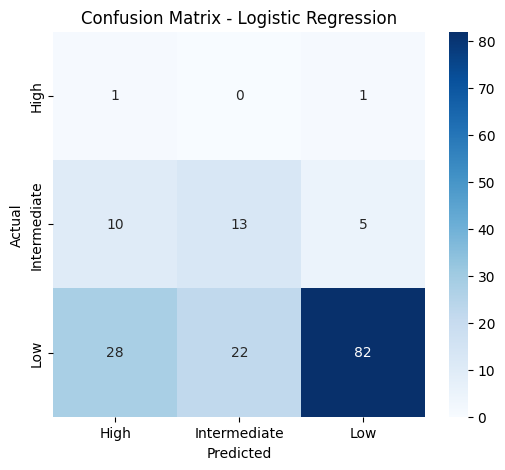

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [ ]:
y_pred_smote = model.predict(X_train_smote)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_train_smote, y_pred_smote)

print(f"Accuracy : {accuracy*100:.2f}%")

Accuracy : 75.38%


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_train_smote,
    y_pred_smote
))

              precision    recall  f1-score   support

           0       0.80      0.86      0.83       306
           1       0.68      0.67      0.67       306
           2       0.78      0.74      0.76       306

    accuracy                           0.75       918
   macro avg       0.75      0.75      0.75       918
weighted avg       0.75      0.75      0.75       918



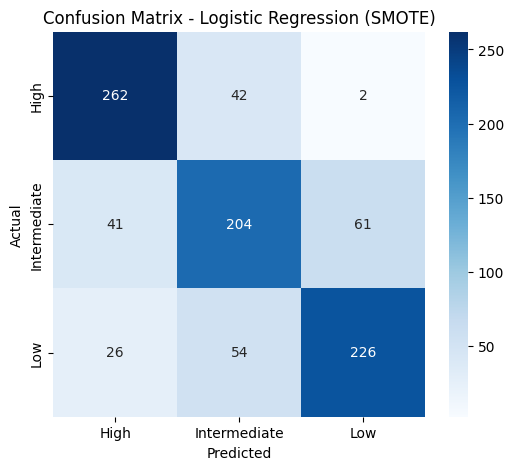

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_train_smote, y_pred_smote)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['High','Intermediate','Low'],
    yticklabels=['High','Intermediate','Low']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression (SMOTE)")

plt.show()

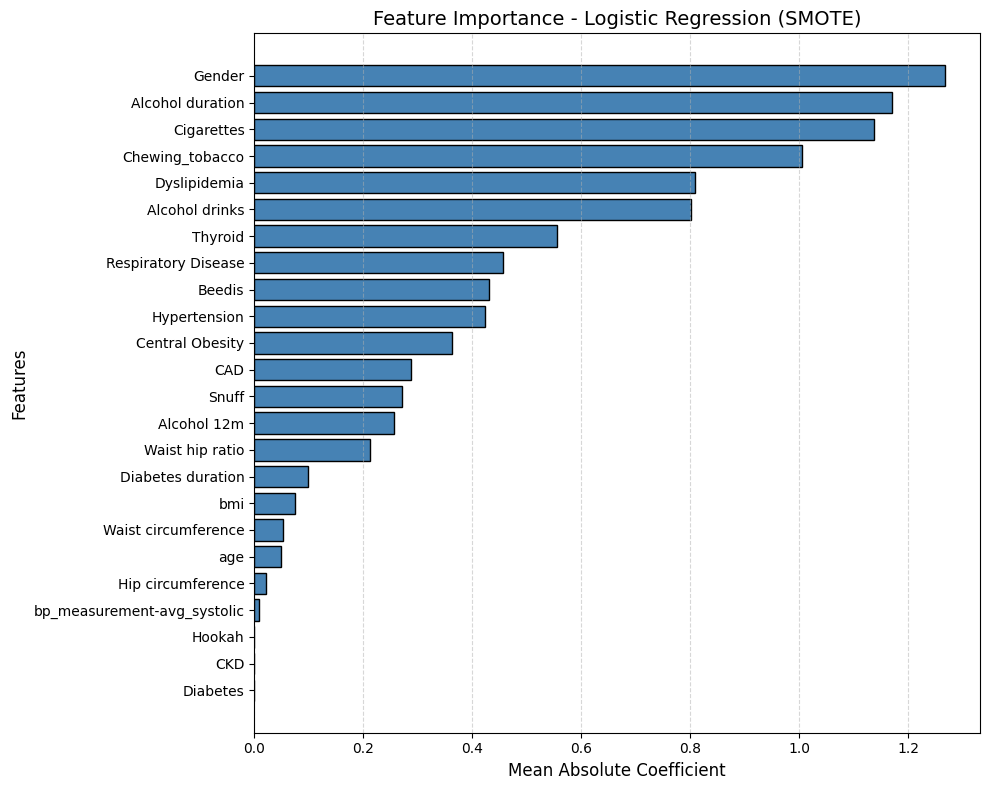

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert SMOTE data to DataFrame (if needed)
X_train_smote_df = pd.DataFrame(X_train_smote, columns=X.columns)

# Calculate feature importance
importance = pd.DataFrame({
    'Feature': X_train_smote_df.columns,
    'Importance': np.mean(np.abs(model.coef_), axis=0)
})

# Sort for plotting
importance = importance.sort_values(by='Importance', ascending=True)

# Plot
plt.figure(figsize=(10,8))

plt.barh(
    importance['Feature'],
    importance['Importance'],
    color='steelblue',
    edgecolor='black'
)

plt.xlabel('Mean Absolute Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Importance - Logistic Regression (SMOTE)', fontsize=14)

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()